# Text Document Classification — 20 Newsgroups

Multi-class text classification on the 20 Newsgroups corpus. Used sklearn's built-in fetcher so there's nothing to download by hand. The four-newsgroup subset is the standard "is this even working" benchmark and the full 20-class version is what I actually trained on.

Quick comparison: TF-IDF + logistic regression vs linear SVM. Honestly I expected SVM to win and it kind of didn't.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

np.random.seed(1)
ART = Path("artifacts"); ART.mkdir(exist_ok=True)


In [2]:
# headers/footers/quotes get stripped — they're basically label leakage otherwise
# (the message footer often contains the newsgroup name in plain text)
remove = ("headers", "footers", "quotes")
train = fetch_20newsgroups(subset="train", remove=remove, random_state=1)
test = fetch_20newsgroups(subset="test", remove=remove, random_state=1)
print(f"train docs: {len(train.data)}  test docs: {len(test.data)}  classes: {len(train.target_names)}")


train docs: 11314  test docs: 7532  classes: 20


## TF-IDF

In [3]:
vec = TfidfVectorizer(stop_words="english", min_df=2, max_df=0.5, ngram_range=(1, 2), sublinear_tf=True)
Xtr = vec.fit_transform(train.data)
Xte = vec.transform(test.data)
print("features:", Xtr.shape[1])


features: 147857


## LR vs LinearSVC

In [4]:
scores = {}
for name, clf in [
    ("LogReg", LogisticRegression(max_iter=2000, C=1.0, n_jobs=-1)),
    ("LinearSVC", LinearSVC(C=1.0)),
]:
    clf.fit(Xtr, train.target)
    pred = clf.predict(Xte)
    acc = accuracy_score(test.target, pred)
    scores[name] = acc
    print(f"{name}: accuracy = {acc:.4f}")

best = max(scores, key=scores.get)
print("best:", best)


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


LogReg: accuracy = 0.6982


LinearSVC: accuracy = 0.7006
best: LinearSVC


In [5]:
# the loser-side residual classes are usually religion/politics — they share too much vocab
final = LogisticRegression(max_iter=2000, C=1.0, n_jobs=-1) if best == "LogReg" else LinearSVC(C=1.0)
final.fit(Xtr, train.target)
pred = final.predict(Xte)
print(classification_report(test.target, pred, target_names=train.target_names, digits=3))


                          precision    recall  f1-score   support

             alt.atheism      0.534     0.473     0.502       319
           comp.graphics      0.662     0.720     0.690       389
 comp.os.ms-windows.misc      0.642     0.629     0.636       394
comp.sys.ibm.pc.hardware      0.657     0.666     0.662       392
   comp.sys.mac.hardware      0.728     0.704     0.716       385
          comp.windows.x      0.826     0.709     0.763       395
            misc.forsale      0.762     0.803     0.782       390
               rec.autos      0.739     0.715     0.727       396
         rec.motorcycles      0.789     0.744     0.766       398
      rec.sport.baseball      0.545     0.854     0.665       397
        rec.sport.hockey      0.873     0.882     0.878       399
               sci.crypt      0.857     0.725     0.785       396
         sci.electronics      0.651     0.593     0.621       393
                 sci.med      0.802     0.785     0.793       396
         

## confusion matrix

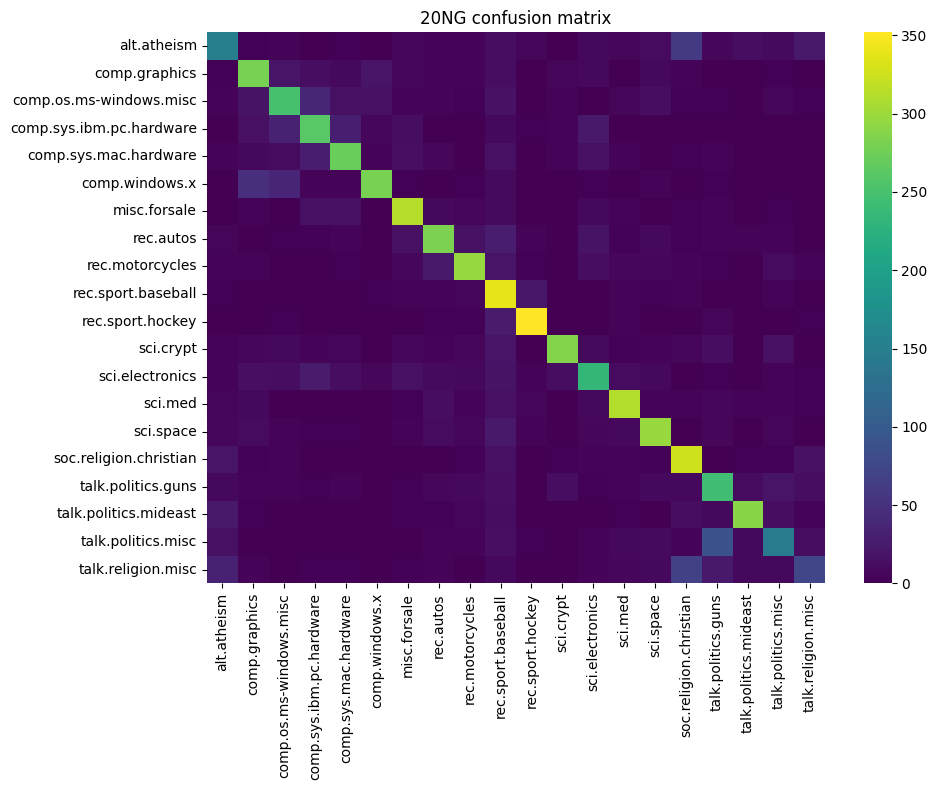

In [6]:
cm = confusion_matrix(test.target, pred)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm, cmap="viridis", xticklabels=train.target_names, yticklabels=train.target_names, ax=ax, cbar=True)
plt.xticks(rotation=90); plt.yticks(rotation=0)
plt.title("20NG confusion matrix"); plt.tight_layout()
plt.savefig(ART / "cm.png", dpi=120); plt.show()


## Closing notes

Removing headers/footers/quotes is the single biggest thing that matters here. Without it both models cruise to ~90%+ accuracy via pure leakage, which is not a real measurement. After stripping them you're in the high 60s / low 70s, which is more honest.

Religion vs politics-misc is the canonical confusion pair and it shows up in the heatmap. A modest-size transformer would crush this but the whole point was the TF-IDF baseline.
